# **Import libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    AdaBoostRegressor
)
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from xgboost import XGBRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import joblib

# **Load the dataset**

In [2]:
df=pd.read_csv("healthinsurance.csv")
df

,age,sex,weight,bmi,hereditary_diseases,no_of_dependents,smoker,city,bloodpressure,diabetes,regular_ex,job_title,claim
0,60.0,male,64,24.3,NoDisease,1,0,NewYork,72,0,0,Actor,13112.6
1,49.0,female,75,22.6,NoDisease,1,0,Boston,78,1,1,Engineer,9567.0
2,32.0,female,64,17.8,Epilepsy,2,1,Phildelphia,88,1,1,Academician,32734.2
3,61.0,female,53,36.4,NoDisease,1,1,Pittsburg,72,1,0,Chef,48517.6
4,19.0,female,50,20.6,NoDisease,0,0,Buffalo,82,1,0,HomeMakers,1731.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,39.0,male,49,28.3,NoDisease,1,1,Florence,54,1,0,FilmMaker,21082.2
14996,39.0,male,74,29.6,NoDisease,4,0,Miami,64,1,0,Student,7512.3
14997,20.0,male,62,33.3,NoDisease,0,0,Tampa,52,1,0,FashionDesigner,1391.5
14998,52.0,male,88,36.7,NoDisease,0,0,PanamaCity,70,1,0,Farmer,9144.6


# **Understand the dataset**

In [3]:
df.shape

(15000, 13)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  14604 non-null  float64
 1   sex                  15000 non-null  object 
 2   weight               15000 non-null  int64  
 3   bmi                  14044 non-null  float64
 4   hereditary_diseases  15000 non-null  object 
 5   no_of_dependents     15000 non-null  int64  
 6   smoker               15000 non-null  int64  
 7   city                 15000 non-null  object 
 8   bloodpressure        15000 non-null  int64  
 9   diabetes             15000 non-null  int64  
 10  regular_ex           15000 non-null  int64  
 11  job_title            15000 non-null  object 
 12  claim                15000 non-null  float64
dtypes: float64(3), int64(6), object(4)
memory usage: 1.5+ MB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,14604.0,39.547521,14.015966,18.0,27.0,40.00,52.000,64.0
weight,15000.0,64.909600,13.701935,34.0,54.0,63.00,76.000,95.0
bmi,14044.0,30.266413,6.122950,16.0,25.7,29.40,34.400,53.1
no_of_dependents,15000.0,1.129733,1.228469,0.0,0.0,1.00,2.000,5.0
smoker,15000.0,0.198133,0.398606,0.0,0.0,0.00,0.000,1.0
bloodpressure,15000.0,68.650133,19.418515,0.0,64.0,71.00,80.000,122.0
diabetes,15000.0,0.777000,0.416272,0.0,1.0,1.00,1.000,1.0
regular_ex,15000.0,0.224133,0.417024,0.0,0.0,0.00,0.000,1.0
claim,15000.0,13401.437620,12148.239619,1121.9,4846.9,9545.65,16519.125,63770.4


In [6]:
for col in df.columns:
    print(col)
    print(80*"-")
    print(df[col].unique())
    print("\n")
    

age
--------------------------------------------------------------------------------
[60. 49. 32. 61. 19. 42. 18. 21. 63. 40. 51. 59. 27. 56. 52. 20. 24. 53.
 38. 54. 64. 50. 46. 55. 36. 44. 62. 48. 31. 43. 47. 41. 22. 45. 57. nan
 23. 58. 28. 34. 26. 35. 25. 37. 33. 29. 30. 39.]


sex
--------------------------------------------------------------------------------
['male' 'female']


weight
--------------------------------------------------------------------------------
[64 75 53 50 89 59 52 55 69 68 45 67 46 76 44 60 82 40 71 61 70 84 51 48
 62 94 41 57 49 85 79 90 72 43 65 91 88 80 74 47 56 54 83 73 81 77 66 58
 86 95 93 78 92 63 42 87 34 36]


bmi
--------------------------------------------------------------------------------
[24.3 22.6 17.8 36.4 20.6 37.9 23.8 26.8  nan 29.6 33.  36.5 24.6 35.7
 18.9 40.3 27.2 41.3 38.4 28.5 31.8 31.3 25.7 25.3 24.8 39.4 25.5 26.9
 24.  37.1 44.8 25.1 32.3 28.7 35.2 26.7 26.4 22.3 25.8 21.9 40.2 38.6
 39.2 28.9 25.9 32.7 29.7 26.  35.6 46.8 34.2 

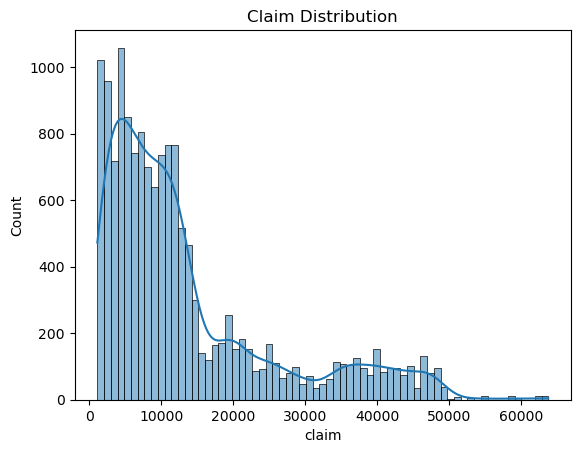

In [7]:
sns.histplot(df['claim'],kde=True)
plt.title('Claim Distribution')
plt.show()

In [8]:
df.select_dtypes(include='number').kurt()

age                -1.250189
weight             -0.866120
bmi                -0.094215
no_of_dependents    0.192328
smoker              0.294695
bloodpressure       5.432755
diabetes           -0.228370
regular_ex         -0.249172
claim               1.470063
dtype: float64

# **Check missing values**

In [9]:
df.isnull().sum()

age                    396
sex                      0
weight                   0
bmi                    956
hereditary_diseases      0
no_of_dependents         0
smoker                   0
city                     0
bloodpressure            0
diabetes                 0
regular_ex               0
job_title                0
claim                    0
dtype: int64

# **Duplicate**

In [10]:
print("Total rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())

Total rows: 15000
Duplicate rows: 1096


In [11]:
df=df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (13904, 13)


# **Check Zero Values**

In [12]:
(df==0.).sum()

age                        0
sex                        0
weight                     0
bmi                        0
hereditary_diseases        0
no_of_dependents        5837
smoker                 11114
city                       0
bloodpressure            703
diabetes                3182
regular_ex             10696
job_title                  0
claim                      0
dtype: int64

In [13]:
df['bloodpressure'] = df['bloodpressure'].replace(0, np.nan)
df['bloodpressure'] = df['bloodpressure'].fillna(df['bloodpressure'].median())

# **EDA Visualization**

 **Numerical Distribution**

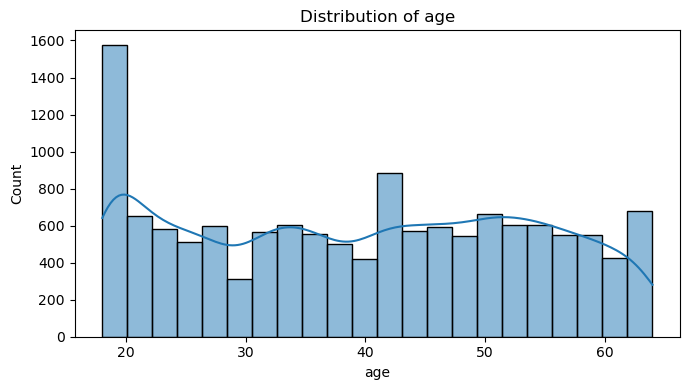

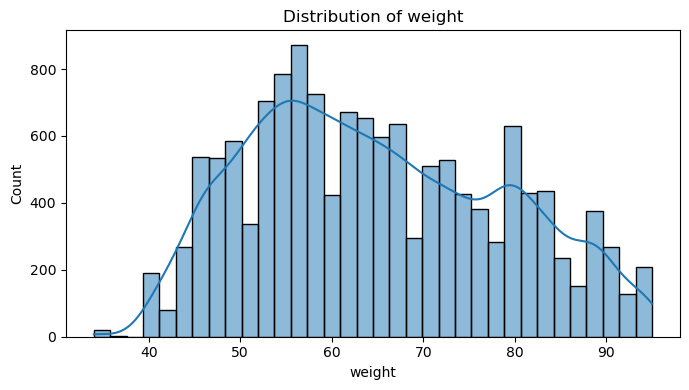

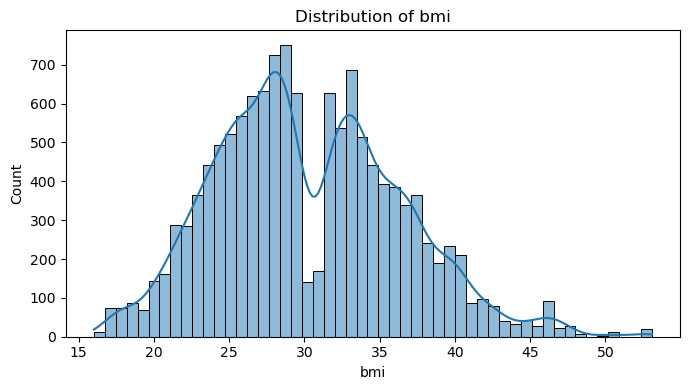

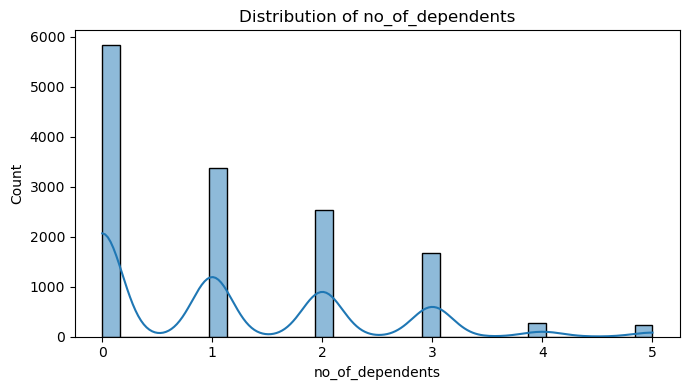

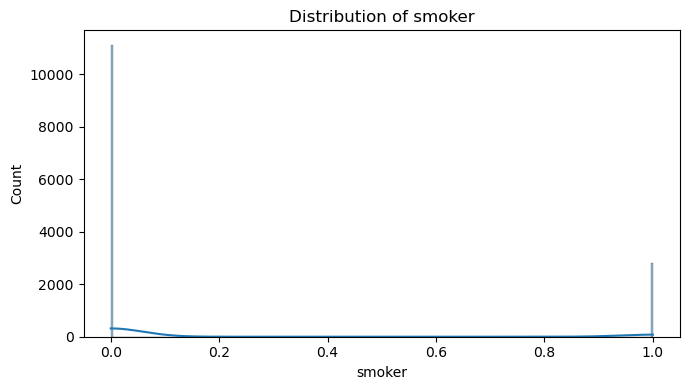

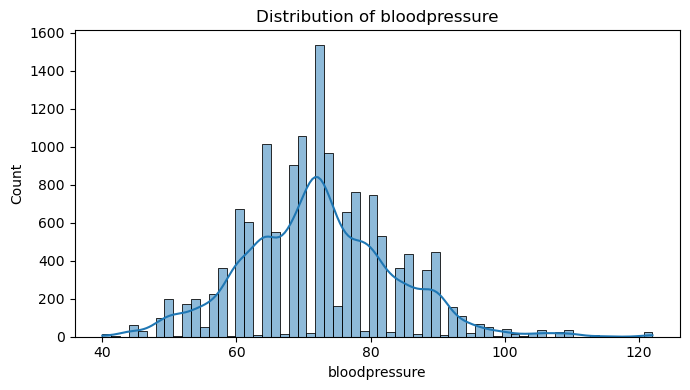

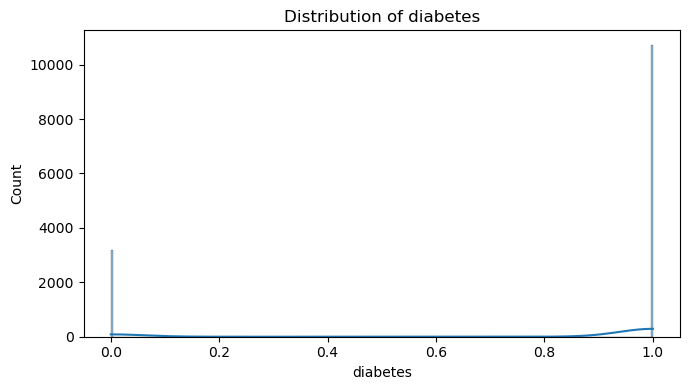

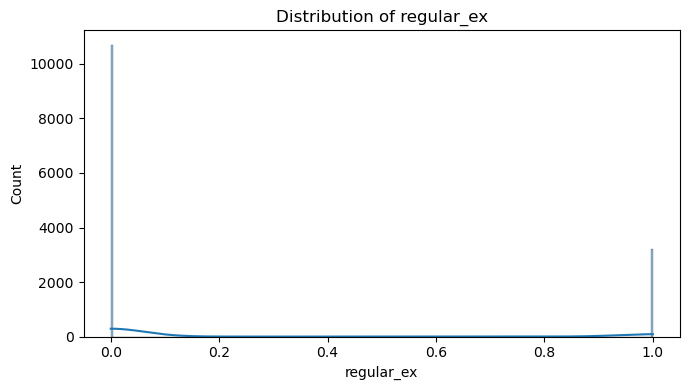

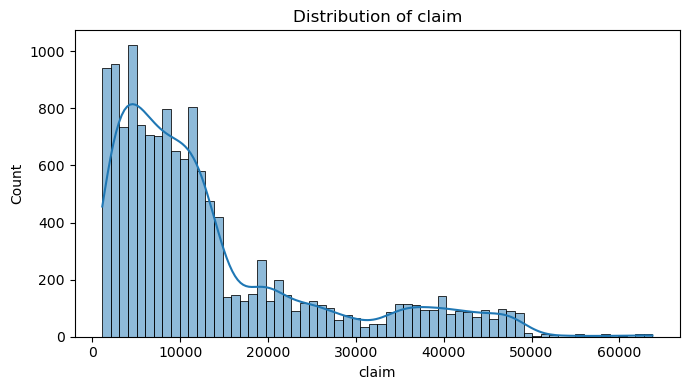

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f'Distribution of {col}')
    plt.tight_layout()
    plt.show()

**Categorical Variables**

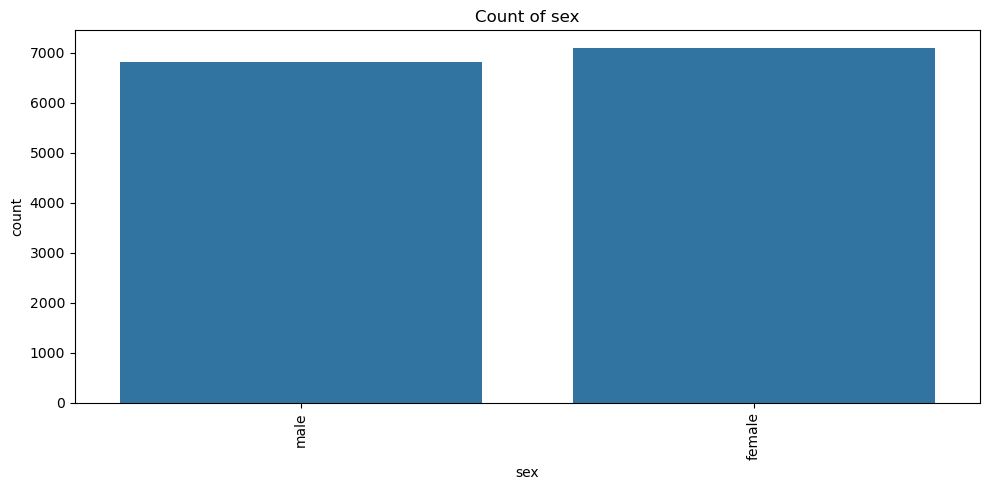

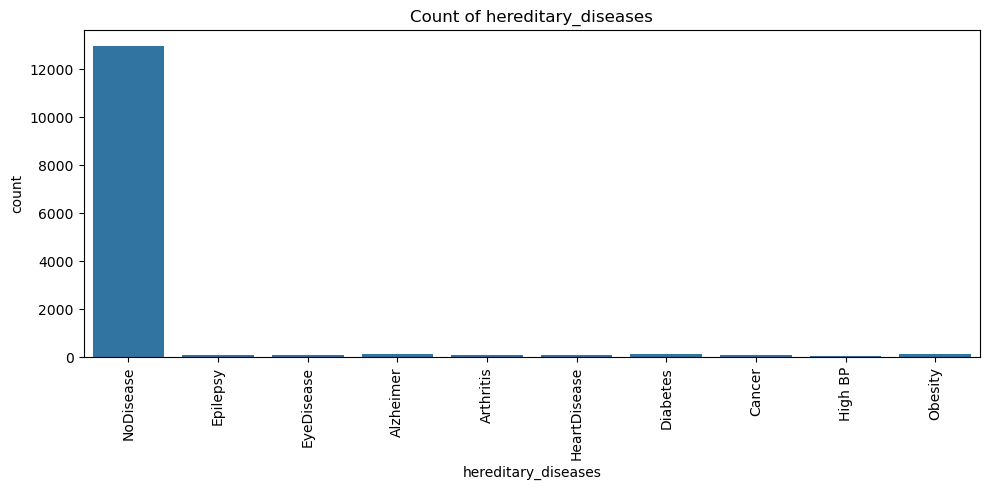

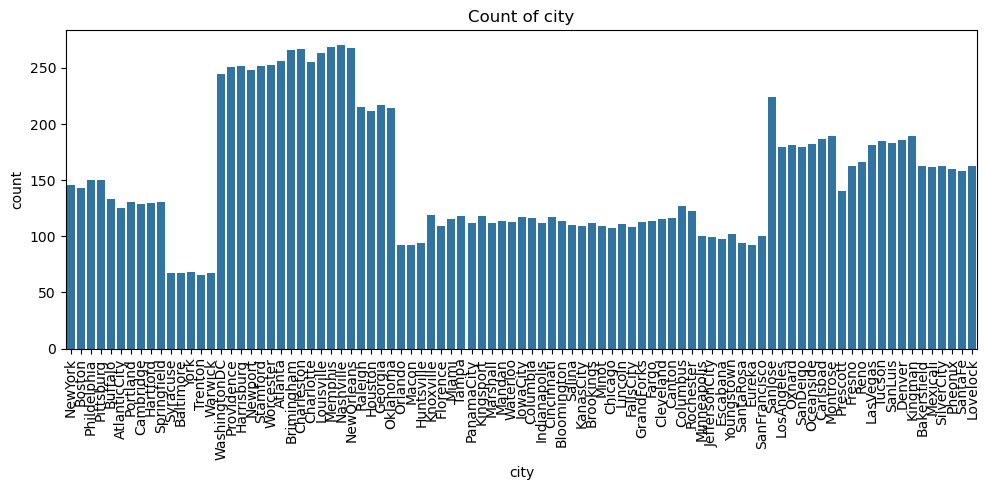

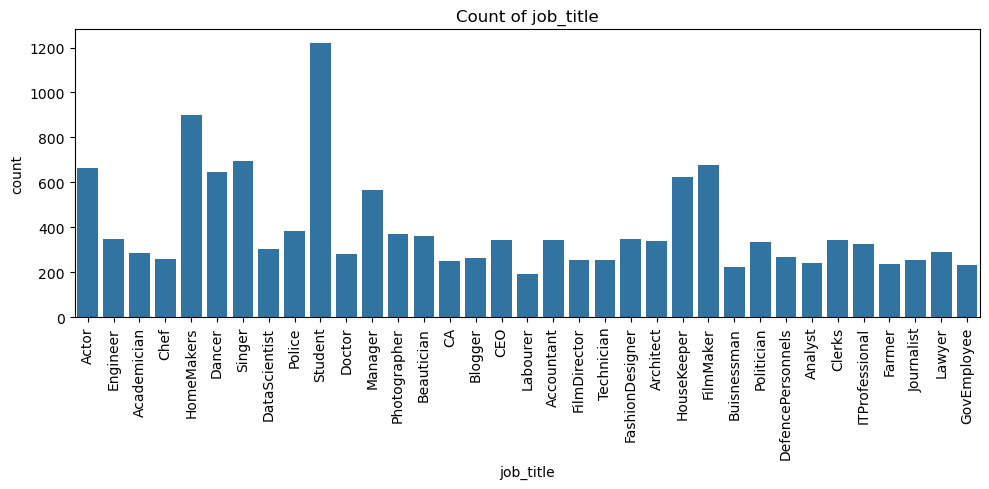

In [15]:
categorical_columns=df.select_dtypes(include="object").columns
for col in categorical_columns:
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, x=col)
    plt.title(f'Count of {col}')
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

# **Outlier Detection**

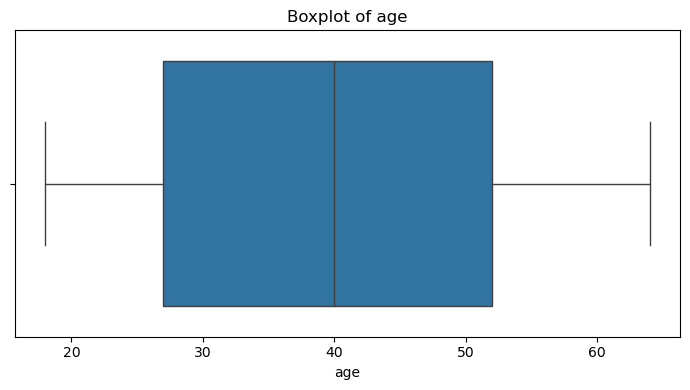

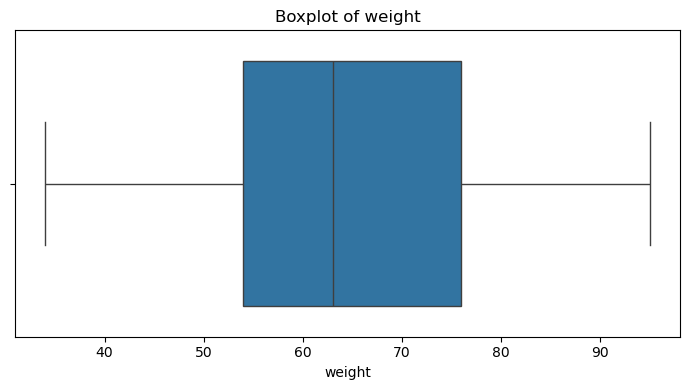

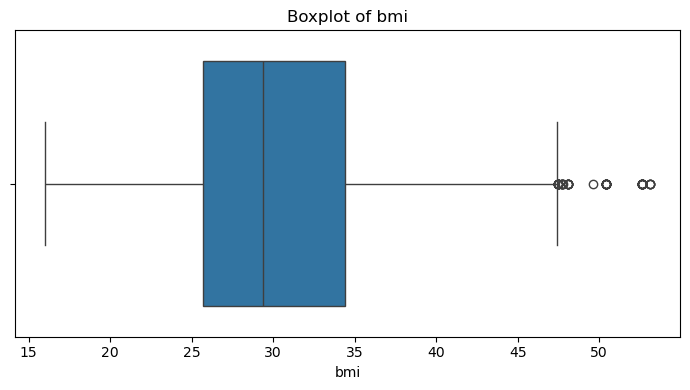

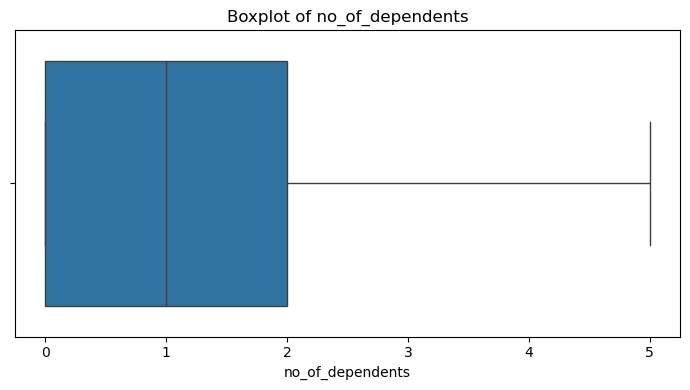

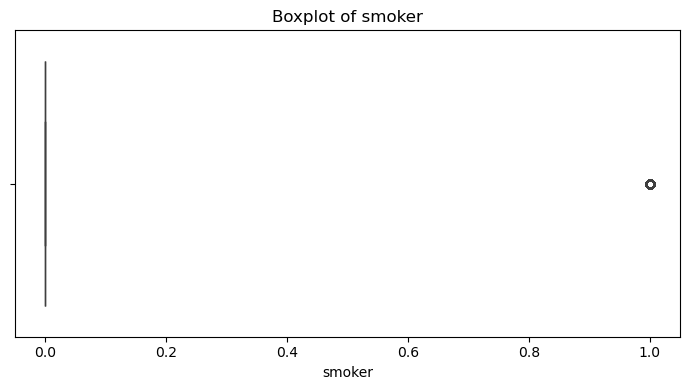

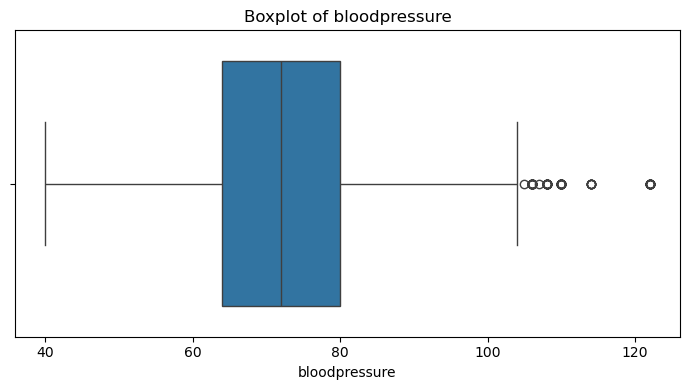

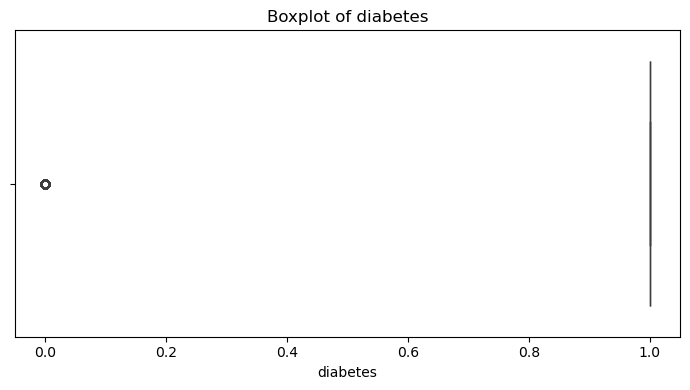

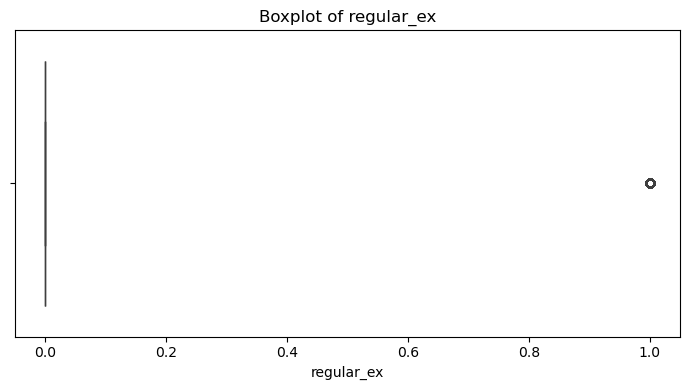

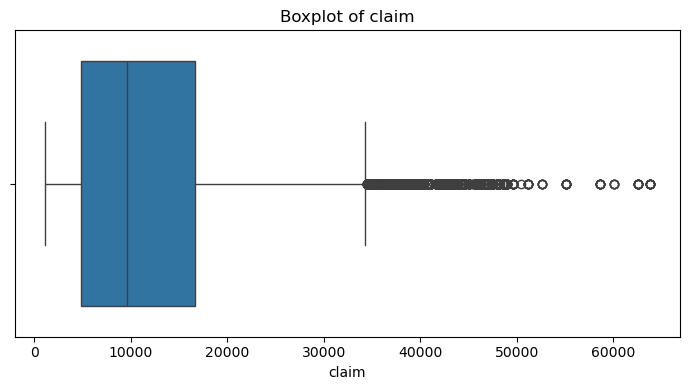

In [16]:
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.tight_layout()
    plt.show()

# **Skewness**

In [17]:
df.select_dtypes(include='number').skew()

age                 0.006109
weight              0.286729
bmi                 0.377468
no_of_dependents    0.931568
smoker              1.495002
bloodpressure       0.343646
diabetes           -1.291012
regular_ex          1.278453
claim               1.489221
dtype: float64

# **Kurtosis**

In [18]:
df.select_dtypes(include='number').kurt()

age                -1.248190
weight             -0.862059
bmi                -0.076433
no_of_dependents    0.204577
smoker              0.235063
bloodpressure       0.786995
diabetes           -0.333336
regular_ex         -0.365610
claim               1.447701
dtype: float64

 **Correlation Heatmap**

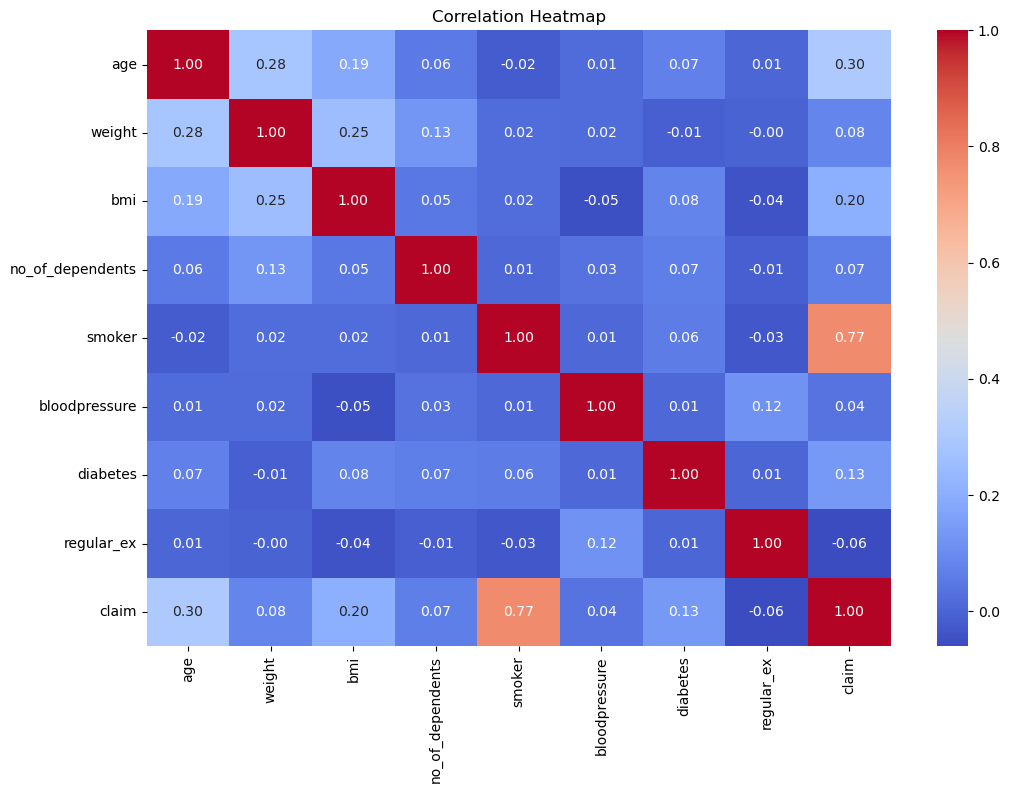

In [19]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

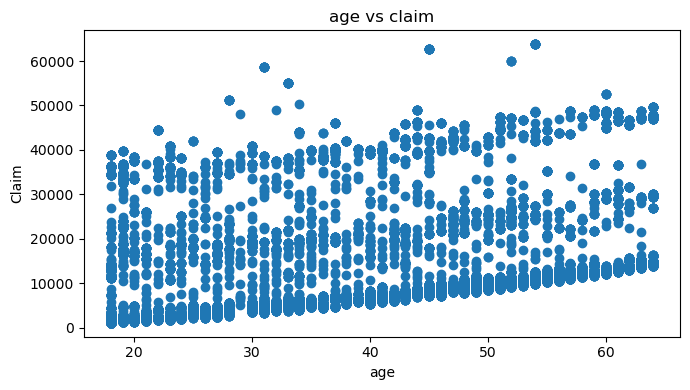

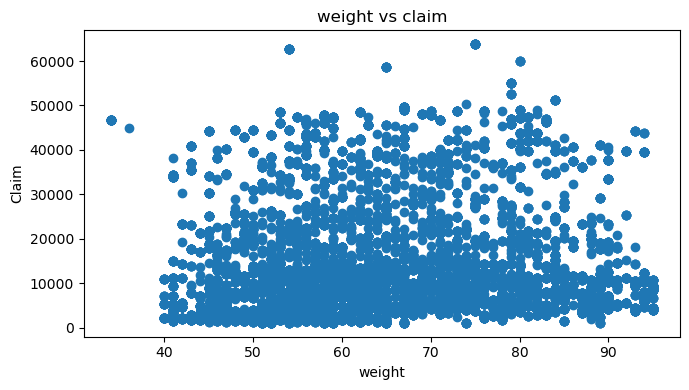

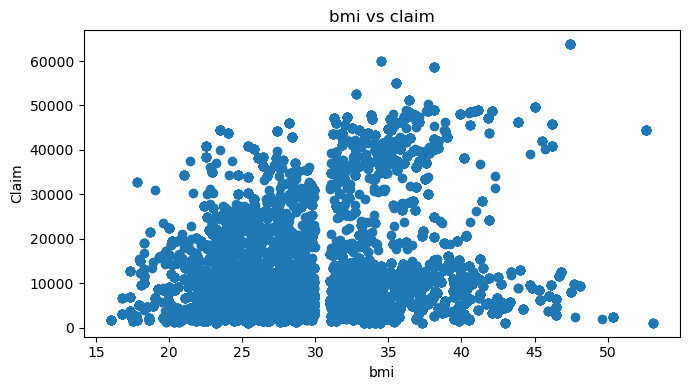

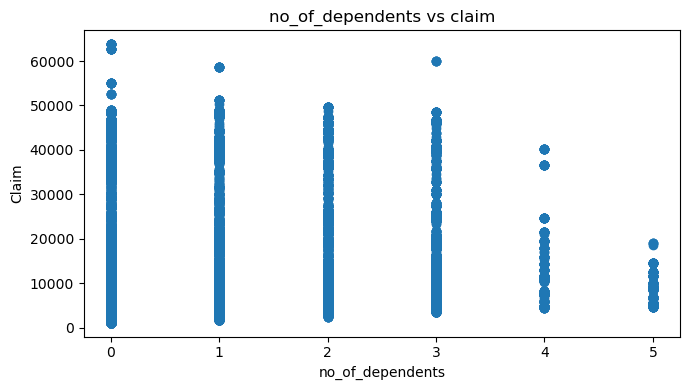

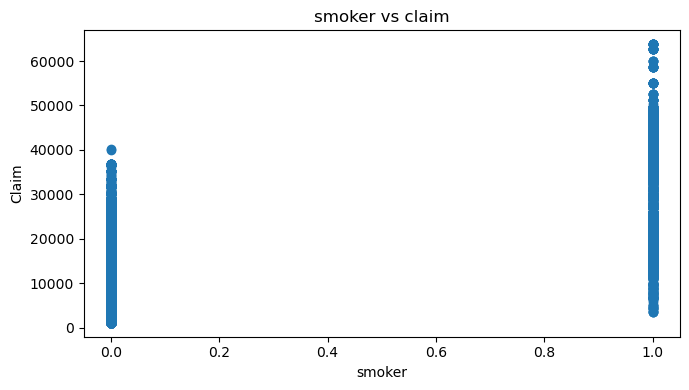

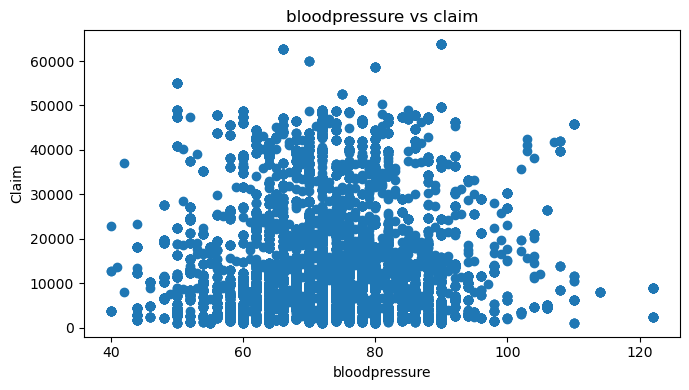

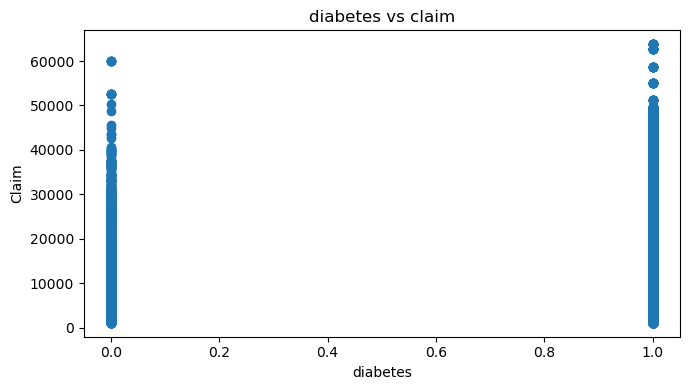

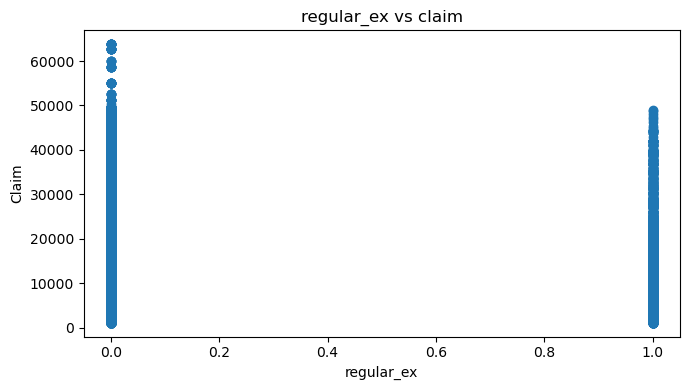

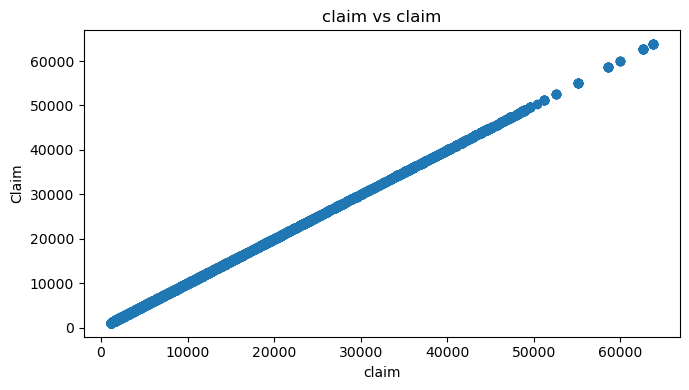

In [20]:
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    plt.figure(figsize=(7, 4))
    plt.scatter(df[col],df["claim"])
    plt.xlabel(col)
    plt.ylabel("Claim")
    plt.title(f'{col} vs claim')
    plt.tight_layout()
    plt.show()

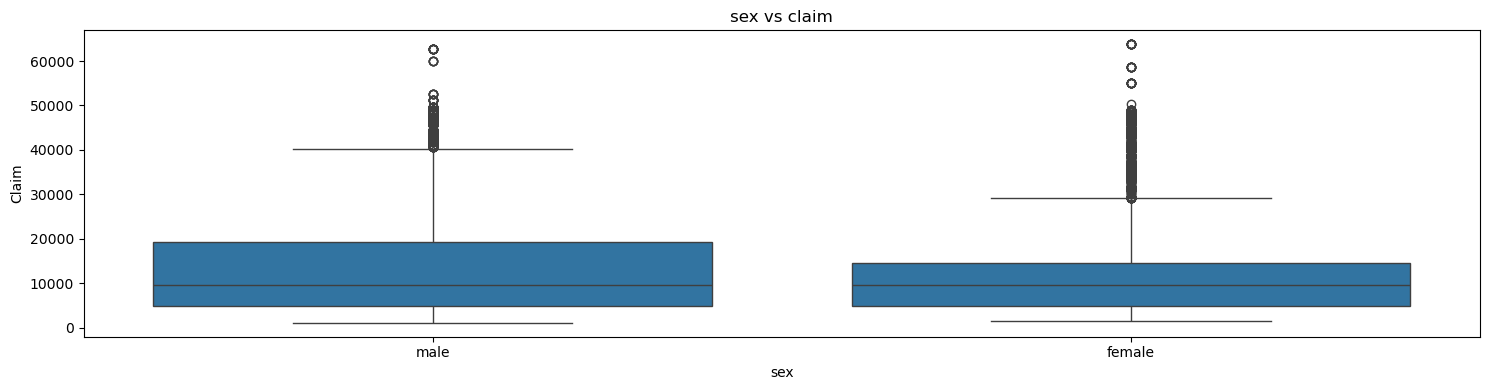

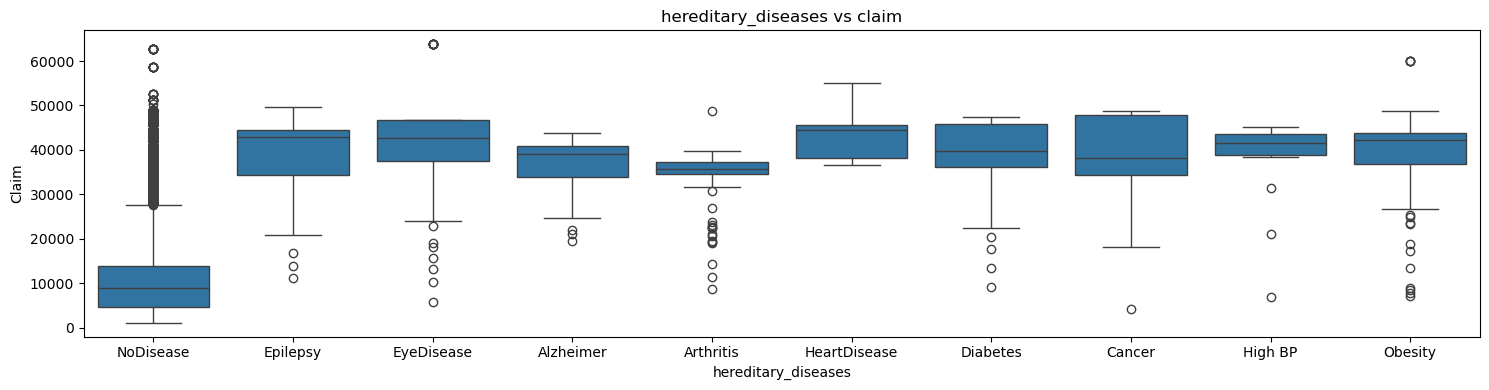

In [21]:
categorical_columns = ["sex","hereditary_diseases"]

for col in categorical_columns:
    plt.figure(figsize=(15, 4))
    sns.boxplot(x=df[col],y=df["claim"])
    plt.xlabel(col)
    plt.ylabel("Claim")
    plt.title(f'{col} vs claim')
    plt.tight_layout()
    plt.show()

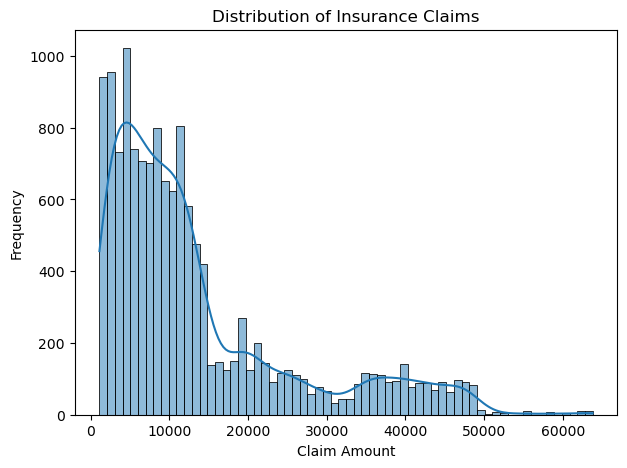

In [22]:
plt.figure(figsize=(7, 5))

sns.histplot(data=df, x='claim', kde=True)

plt.title("Distribution of Insurance Claims")
plt.xlabel("Claim Amount")
plt.ylabel("Frequency")
plt.show()

# **Separate Features and Target**

In [23]:
X = df.drop("claim", axis=1)

y = df["claim"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (13904, 12)
y Shape: (13904,)


# **Identify Numerical and Categorical Columns**

In [24]:
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Columns:")
print(numeric_features)

print("\nCategorical Columns:")
print(categorical_features)

Numerical Columns:
['age', 'weight', 'bmi', 'no_of_dependents', 'smoker', 'bloodpressure', 'diabetes', 'regular_ex']

Categorical Columns:
['sex', 'hereditary_diseases', 'city', 'job_title']


# **Split the Dataset**

In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (11123, 12)
Testing Data: (2781, 12)


# **Handle Missing Values and Encode Categorical Columns**

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [27]:
# Numerical: Missing value handling + Standard Scaling
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical: Missing value handling + One-Hot Encoding
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing completed!")
preprocessor

Preprocessing completed!


,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


In [28]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (11123, 146)
Processed testing shape: (2781, 146)


In [29]:
models = {
    "Linear Regression": LinearRegression(),
    
    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),
    
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),
    
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ),
    
    "Support Vector": SVR(),
    
    "KNN": KNeighborsRegressor(
        n_neighbors=5
    ),
    
    "AdaBoost": AdaBoostRegressor(
        n_estimators=100,
        random_state=42
    ),
    
    "XGBoost": XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    )
}

In [30]:
results = []

for name, model in models.items():

    # Train the model
    model.fit(X_train_processed, y_train)

    # Prediction
    y_pred = model.predict(X_test_processed)

    # Evaluation metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

In [31]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="R2 Score",
    ascending=False
)

results_df

,Model,MAE,MSE,RMSE,R2 Score
2,Random Forest,520.948015,4.241207e+06,2059.419129,0.971658
5,KNN,576.788019,5.857274e+06,2420.180653,0.960859
1,Decision Tree,463.599497,6.769718e+06,2601.868214,0.954762
7,XGBoost,1623.600286,8.600155e+06,2932.602043,0.942530
3,Gradient Boosting,2758.881138,2.054668e+07,4532.844162,0.862698
0,Linear Regression,3930.874709,3.563607e+07,5969.595447,0.761864
6,AdaBoost,8798.760325,8.863027e+07,9414.364974,0.407733
4,Support Vector,8235.768884,1.618141e+08,12720.615688,-0.081314


In [32]:
best_model = results_df.iloc[0]

print("Best Model:", best_model["Model"])
print("R2 Score:", best_model["R2 Score"])
print("MAE:", best_model["MAE"])
print("RMSE:", best_model["RMSE"])

Best Model: Random Forest
R2 Score: 0.9716583621228322
MAE: 520.9480154620724
RMSE: 2059.419128827502


# **Hyperparameter Tuning**

In [33]:
best_two_models = {
    "Random Forest": RandomForestRegressor(
        random_state=42
    ),
    
    "KNN": KNeighborsRegressor()
}

print("Models selected for Hyperparameter Tuning:")
print("1. Random Forest")
print("2. KNN")

Models selected for Hyperparameter Tuning:
1. Random Forest
2. KNN


In [34]:
param_grids = {

    "Random Forest": {
        "n_estimators": [100, 200, 300],
        "max_depth": [None, 10, 20],
        "min_samples_split": [2, 5],
        
    },

    "KNN": {
        "n_neighbors": [3, 5, 7, 9, 11],
        "weights": ["uniform", "distance"],
        "p": [1, 2]
    }
}

In [35]:
tuned_results = []
best_models = {}
for name, model in best_two_models.items():
    print("Tuning:", name)
    
    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        cv=5,
        scoring="neg_root_mean_squared_error",
        n_jobs=-1
    )

    grid.fit(X_train_processed, y_train)
    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test_processed)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    best_models[name] = best_model
    tuned_results.append({
        "Model": name,
        "Best Parameters": grid.best_params_,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

Tuning: Random Forest
Tuning: KNN


In [ ]:
import pandas as pd
tuned_results_df = pd.DataFrame(tuned_results)
tuned_results_df = tuned_results_df.sort_values( by="R2 Score", ascending=False ) 
tuned_results_df

In [ ]:
best_model_name = tuned_results_df.iloc[0]["Model"] 
best_model = best_models[best_model_name] 
print("best tuned model:", best_model_name) 
print( "best parameters:", tuned_results_df.iloc[0]["Best Parameters"] ) 
print( "mae:", tuned_results_df.iloc[0]["MAE"] ) 
print( "mse:", tuned_results_df.iloc[0]["MSE"] )
print( "rmse:", tuned_results_df.iloc[0]["RMSE"] ) 
print( "r2 score:", tuned_results_df.iloc[0]["R2 Score"] )

In [ ]:
# Final Results

final_results = results_df.copy()
# Replace Random Forest with tuned result
for model_name in ["Random Forest", "KNN"]:
    tuned_row = tuned_results_df[
        tuned_results_df["Model"] == model_name
    ].iloc[0]

    final_results.loc[
        final_results["Model"] == model_name,
        "MAE"
    ] = tuned_row["MAE"]

    final_results.loc[
        final_results["Model"] == model_name,
        "MSE"
    ] = tuned_row["MSE"]

    final_results.loc[
        final_results["Model"] == model_name,
        "RMSE"
    ] = tuned_row["RMSE"]

    final_results.loc[
        final_results["Model"] == model_name,
        "R2 Score"
    ] = tuned_row["R2 Score"]

final_results = final_results[
    [
        "Model",
        "MAE",
        "MSE",
        "RMSE",
        "R2 Score"
    ]
]

final_results

In [ ]:
final_prediction = best_model.predict( X_test_processed ) 
print("final model:", best_model_name) 
print( "MAE:", mean_absolute_error( y_test, final_prediction ) ) 
print( "MAE:", mean_squared_error( y_test, final_prediction ) ) 
print( "RMSE:", np.sqrt( mean_squared_error( y_test, final_prediction ) ) ) 
print( "R2 score:", r2_score( y_test, final_prediction ) )

In [ ]:
# actual vs predicted 
best_model = best_models["Random Forest"] 
y_pred = best_model.predict(X_test_processed) 
actual_vs_predicted = pd.DataFrame({ "actual": y_test.values, "predicted": y_pred }) 
actual_vs_predicted.head()

In [ ]:
# Actual vs Predicted Plot

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred)

plt.xlabel("Actual Claim")
plt.ylabel("Predicted Claim")
plt.title("Actual vs Predicted Values (Random Forest)")
# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle="--"
)

plt.show()

In [ ]:
import joblib
joblib.dump(best_model, "random_forest_model.pkl")
print("Model Saved Successfully!")

In [ ]:
joblib.dump(preprocessor, "preprocessor.pkl")
print("preprocessor saved successfully!")